# v105 ball contacts: the bridge's ball-raceway contacts of a solved bearing against r02 Hertz

**Question.** Does `slippy_bridge` (`DeepGrooveBallContact.from_bearing`, `AngularContactBallContact.from_bearing`)
build the right contact for every loaded ball of a bearing AxisForge has solved? A check of the TRANSFER
AxisForge -> bridge, not of Hertz (both sides run `hertz_full`): the element's `Q`, `phi`, `alpha` against AxisForge;
the bridge's Hertz `a`, `b`, `p0`, `delta` against r02 of the ball and groove from AxisForge's attributes at its `Q_j`;
the size of each contact; the Hertz series of the two contacts. **Literature.** Hamrock 1983 sec. 14.2 contacts
(PDF p. 44-46): his printed radii are the independent judge.

**Criteria (README section 6, revised after review).** C0 exact; C1-C4 and S1 within 1e-7 (both `hertz_full`;
RC-01), judged wherever the element is at `alpha_0`, RECORD elsewhere (SB-48); the size of the contact RECORD
(R5-88); Hamrock's radii to half a unit of the printed digit, his other contact values RECORD (R5-09, R5-87).

In [1]:
from IPython.display import Image, display
from axisforge.outputs._format import format_table

from studies.v100_dry_contact.v105_ball_contacts import study

out = study.run()
fig = {p.stem.removeprefix("v105_"): p for p in out["figures"]}

## 1. The contacts around the bearing (6210, zero clearance, F_r 1000 N)
Open markers: the bridge's Hertz of each ball's inner and outer contact; lines: r02 of the same ball and groove from
AxisForge's attributes. The inner contact (convex race) is smaller and carries the higher pressure.

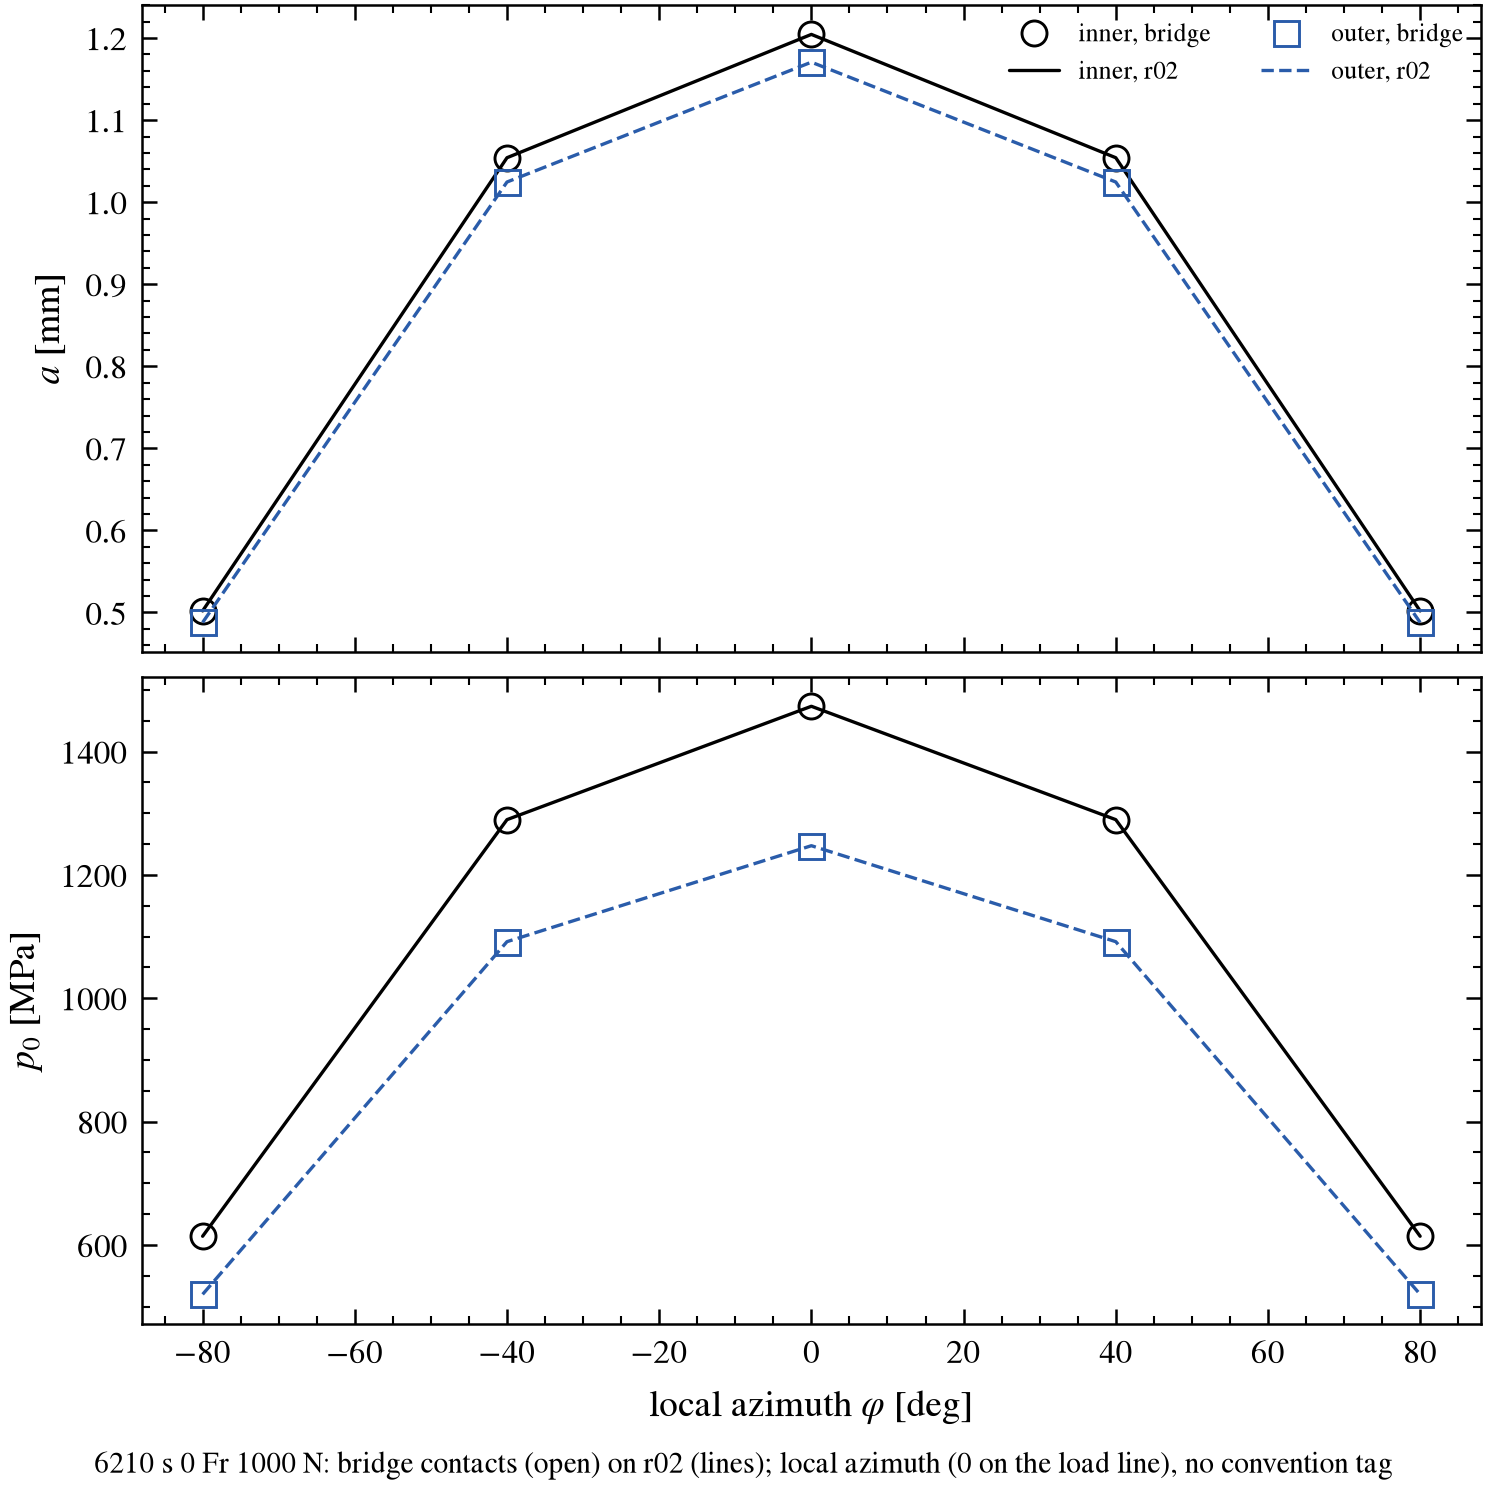

In [2]:
display(Image(filename=str(fig["bearing_loads_load_zone_sweep_around_6210"])))

## 2. Judged and recorded rows; the error does not depend on the size
The bridge and r02 differ by 1e-10 (inner) and 1e-12 (outer) at every load: SlipPY's root tolerance (RC-01), not
the geometry. Judged at every load where the element runs at `alpha_0`; C0 (load, azimuth, angle) is exact.

                    case   race  j   Q [N]   a/r1  id                                                quantity    rel err  verdict
------------------------  -----  -  ------  -----  --  ------------------------------------------------------  ---------  -------
       6210 s 0 Fr 100 N  inner  0    48.7  0.088  C0                                        Q of the element   0.00e+00     PASS
       6210 s 0 Fr 100 N  inner  0    48.7  0.088  C0                                      phi of the element   0.00e+00     PASS
       6210 s 0 Fr 100 N  inner  0    48.7  0.088  C0                                    alpha of the element   0.00e+00     PASS
       6210 s 0 Fr 100 N  inner  0    48.7  0.088  C1                                                       a  -4.88e-11     PASS
       6210 s 0 Fr 100 N  inner  0    48.7  0.088  C3                                                      p0  -8.09e-11     PASS
       6210 s 0 Fr 100 N  outer  0    48.7  0.086  C0                                     

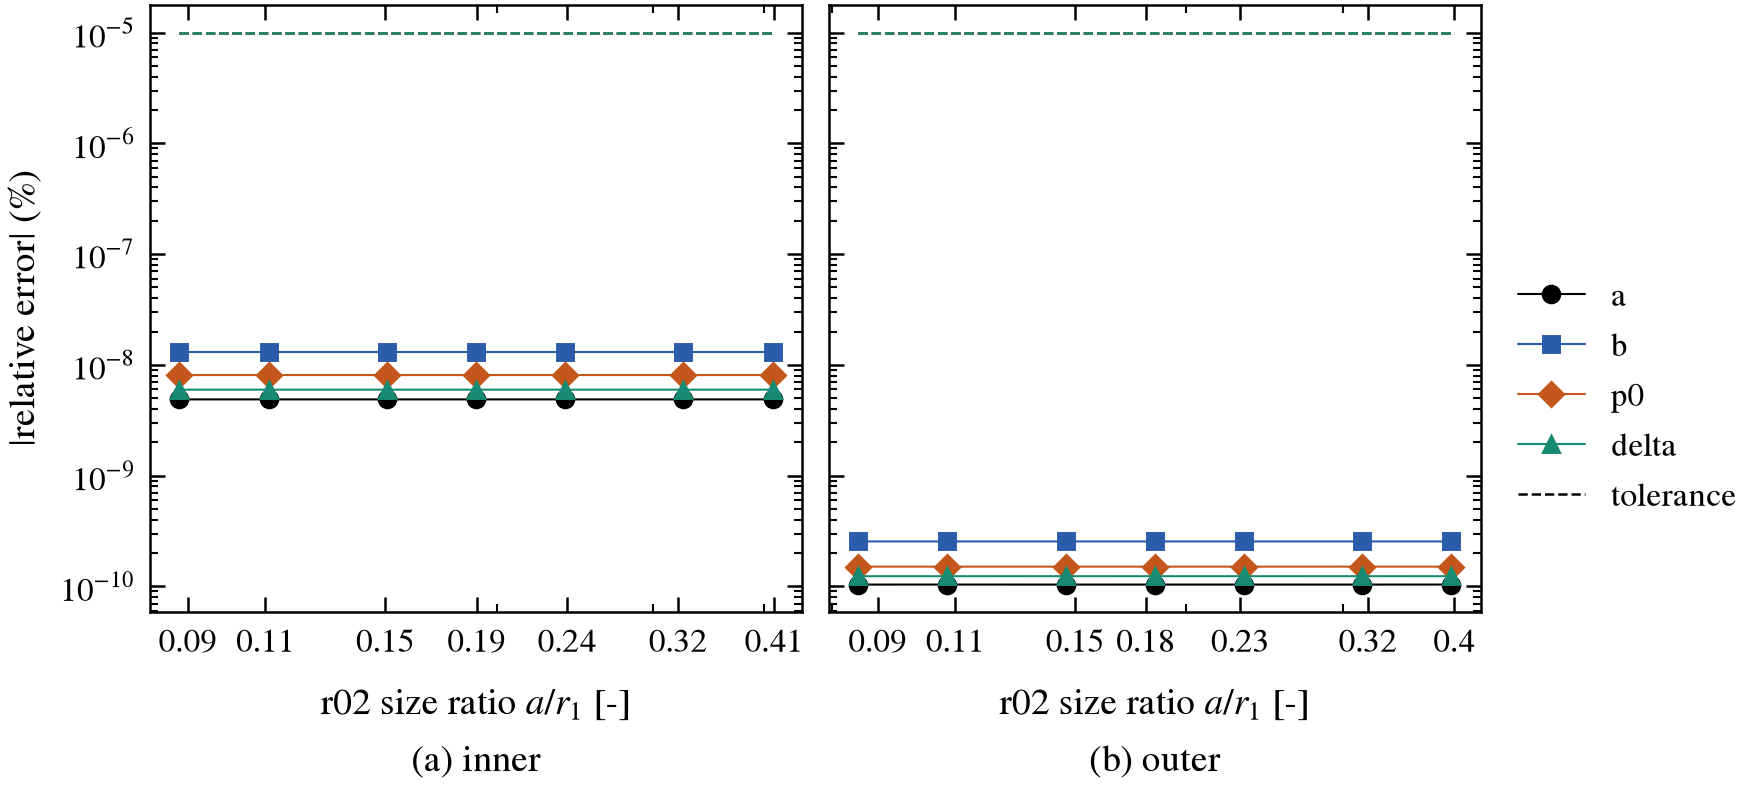

In [3]:
cols = (("label", "case", "s"), ("race", "race", "s"), ("j", "j", "d"), ("Q_N", "Q [N]", ".1f"),
        ("size_ratio_r02", "a/r1", ".3f"), ("id", "id", "s"), ("quantity", "quantity", "s"), ("rel_err", "rel err", ".2e"),
        ("verdict", "verdict", "s"))
print(format_table(cols, [r for r in out["check"] if r["j"] == 0 and r["id"] in ("C0", "C1", "C3", "S1", "S2")]))
display(Image(filename=str(fig["contact_relative_errors_conformity"])))

## 3. Validity: r02's per-body size against the bridge's
r02 measures the contact against each body (`a / r1`, the ball governs; `a / r_g` is 3.8 % lower); the bridge
against the relative radii (SB-07). For a ball in a 0.52 groove the two differ by a factor of about 7: the bridge
calls a contact valid that r02 puts far outside 0.1 already at a few hundred newtons. Johnson asks both; the 0.1
threshold is policy (OPEN R5-88), and bearing practice uses Hertz above it.

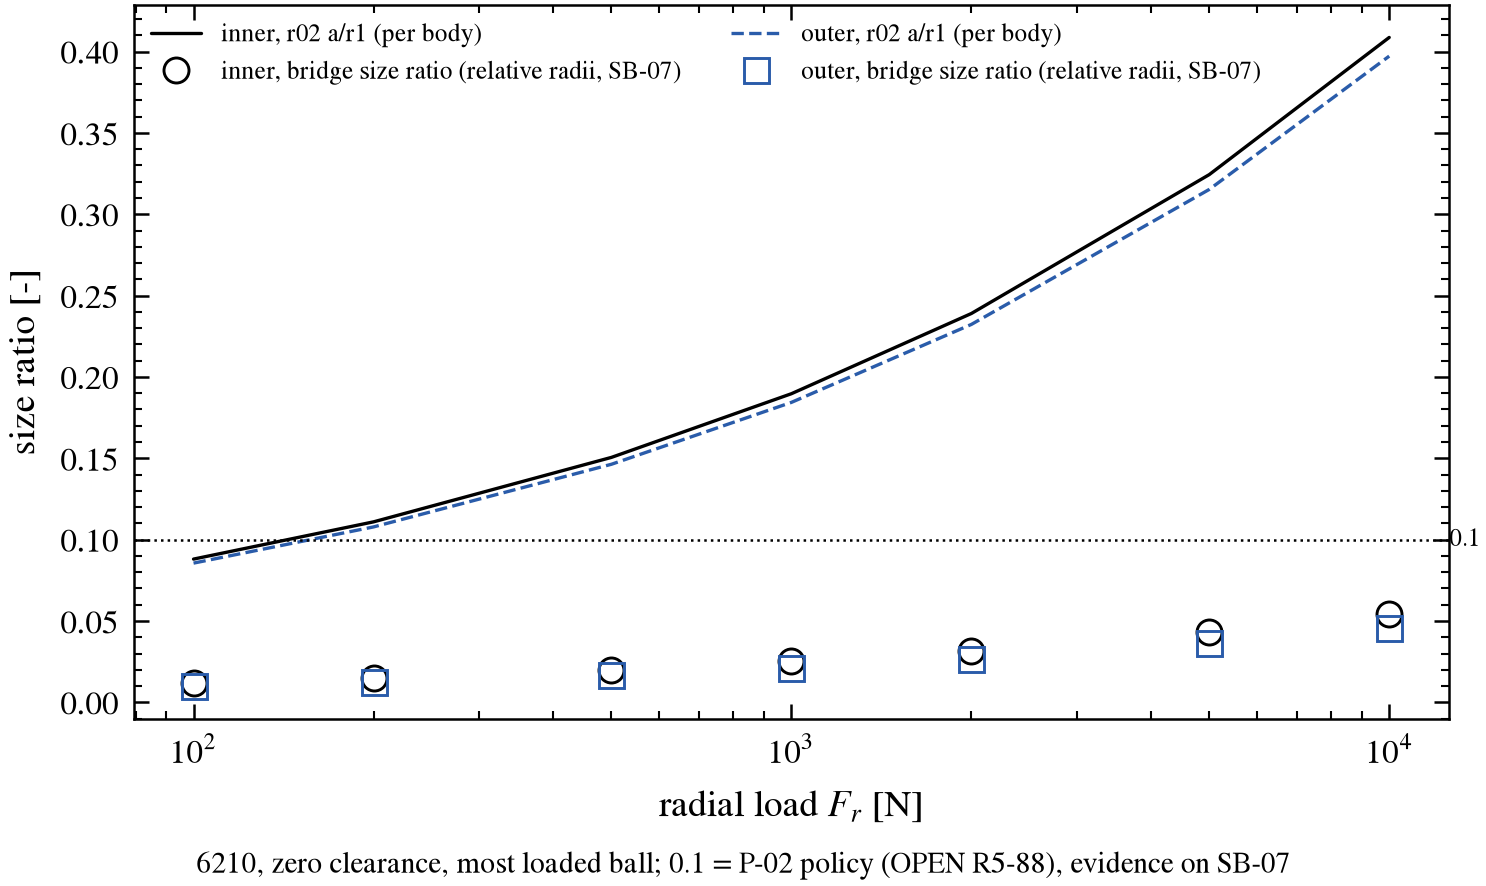

In [4]:
display(Image(filename=str(fig["bearing_loads_load_zone_sweep_validity"])))

## 4. RECORD: elements away from alpha_0 (clearance, angular contact)
With clearance the balls run at `alpha_j = 0` while AxisForge's radii (and `c_p`) are at `alpha_0`; the bridge builds
the raceway at `alpha_j` (SB-48). The difference is a few 1e-3 in `b`, `p0` and below 1e-4 in the series stiffness.

In [5]:
print(format_table(cols, [r for r in out["check"] if r["role"].startswith("RECORD") and r["j"] == 0]))

                    case   race  j   Q [N]   a/r1  id                                                                                quantity    rel err  verdict
------------------------  -----  -  ------  -----  --  --------------------------------------------------------------------------------------  ---------  -------
  6210 s 20 um Fr 5000 N  inner  0  2629.7  0.333  C0                                                                        Q of the element   0.00e+00     PASS
  6210 s 20 um Fr 5000 N  inner  0  2629.7  0.333  C0                                                                      phi of the element   0.00e+00     PASS
  6210 s 20 um Fr 5000 N  inner  0  2629.7  0.333  C0                                                                    alpha of the element   0.00e+00     PASS
  6210 s 20 um Fr 5000 N  inner  0  2629.7  0.333  C1                                                                                       a   3.27e-04   RECORD
  6210 s 20 um Fr 5000 N  in

## 5. Literature: Hamrock 1983 sec. 14.2

In [6]:
print(format_table((("id", "id", "s"), ("quantity", "quantity", "s"), ("measured", "computed", ".6g"),
                    ("reference", "printed", ".6g"), ("rel_err", "rel err", ".2e"), ("verdict", "verdict", "s"),
                    ("note", "note", "s")), out["literature"]))

 id                                                           quantity     computed    printed    rel err  verdict                                                                                                                                                                                                                                     note
---  -----------------------------------------------------------------  -----------  ---------  ---------  -------  ---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
 L1                                                 R_x inner (bridge)   0.00510914    0.00511  -1.69e-04     PASS                                                                                                                                                                                              